# EDA: OSM Flock camera locations (2026-10-30 snapshot)

Personal exploratory analysis of `data/raw/flock_osm/osm_flock_us_locations_2026-10-30.csv`,
following `docs/REPRODUCIBLE_EDA.md`.

- **Primary dataset:** Flock Safety license plate reader (ALPR) cameras mapped in
  OpenStreetMap (OSM), one row per mapped camera. This is a frozen snapshot, so a
  rerun reads the same file.
- **Secondary dataset:** Census ACS 2020–2024 5-year estimates by census tract
  (population, median household income, race/ethnicity), joined to cameras
  through the 2024 TIGER/Line tract shapes.
- **Important:** `timestamp` is the date of each camera's *last edit* in OSM. It is
  not when the camera was installed, and not when it was first mapped.

Research questions (from `README.md`):
1. Where are mapped Flock cameras, and how has the mapping grown over time?
2. Is mapped camera density associated with community characteristics?
3. Is mapped camera density associated with political voting patterns?

In [1]:
import json
# Used to read the all_tags column, which stores every OSM tag as JSON text.

from pathlib import Path
# Used to build file paths from the project root.

import geopandas as gpd
# Used to read census tract shapes and place each camera inside a tract.

import matplotlib.pyplot as plt
# Used to draw every plot.

import numpy as np
# Used for plot bins and log scales.

import pandas as pd
# Only needed to combine GeoPandas tables (GeoPandas is built on pandas).

import polars as pl
# Used for every table in this notebook.

from cs418_flock_research.loaders.load_osm_locations import load_osm_locations
# Project loader: reads the raw CSV without cleaning it.

In [2]:
# Find the project root (the folder holding pyproject.toml), so the paths
# below work no matter which folder Jupyter was started from.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Could not find pyproject.toml above the current folder.")
    ROOT = ROOT.parent

CAMERAS_CSV = ROOT / "data" / "raw" / "flock_osm" / "osm_flock_us_locations_2026-10-30.csv"
ACS_DIR = ROOT / "data" / "raw" / "census"
POPULATION_CSV = ACS_DIR / "population" / "2024" / "ACSDT5Y2024.B01003-Data.csv"
INCOME_CSV = ACS_DIR / "median_household_income" / "2024" / "ACSDT5Y2024.B19013-Data.csv"
RACE_CSV = ACS_DIR / "race_ethnicity" / "2024" / "ACSDT5Y2024.B03002-Data.csv"
TRACT_DIR = ROOT / "data" / "external" / "census_boundaries" / "2024"

# The date in the file name. Edits after this date are checked in Step 1.
SNAPSHOT_DATE = "2026-10-30"

# Stop early with a clear message if any input is missing.
for input_path in [CAMERAS_CSV, POPULATION_CSV, INCOME_CSV, RACE_CSV, TRACT_DIR]:
    if not input_path.exists():
        raise FileNotFoundError(f"Missing input: {input_path}")

# Readable tables and plots.
pl.Config.set_tbl_rows(15)
pl.Config.set_fmt_str_lengths(45)
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11, "axes.titlesize": 13})
print("Project root:", ROOT)

Project root: C:\Users\awaid\OneDrive\Desktop\D\UIC\UIC_Fa26\CS418\cs418-flock-research


## Step 1: Dataset profile

### 1A. OSM camera locations (primary)

In [3]:
cameras = load_osm_locations(CAMERAS_CSV)
cameras.shape

(112830, 20)

**Observation:** The file has 112,830 rows (one per mapped camera) and 20 columns.

In [4]:
# Duplicates: whole rows, OSM ids, and cameras placed on the exact same spot.
row_count = cameras.height
unique_row_count = cameras.unique().height
unique_id_count = cameras["osm_id"].n_unique()
shared_spot_rows = cameras.filter(pl.struct("lat", "lon").is_duplicated()).height
shared_spot_count = cameras.filter(pl.struct("lat", "lon").is_duplicated()).select("lat", "lon").unique().height

print(f"Rows: {row_count:,}   unique rows: {unique_row_count:,}   unique osm_id: {unique_id_count:,}")
print(f"Rows sharing exact coordinates with another row: {shared_spot_rows:,} "
      f"({shared_spot_count:,} distinct spots)")

Rows: 112,830   unique rows: 112,830   unique osm_id: 112,830
Rows sharing exact coordinates with another row: 1,877 (884 distinct spots)


**Observation:** There are no duplicate rows, and all 112,830 `osm_id` values are unique. But 1,877 rows share their exact coordinates with another row (884 spots). These can be several cameras on one pole, or one camera mapped twice; the data cannot tell which.

In [5]:
cameras.schema

Schema([('osm_type', String),
        ('osm_id', String),
        ('lat', Float64),
        ('lon', Float64),
        ('timestamp', String),
        ('version', Int64),
        ('changeset', Int64),
        ('user', String),
        ('man_made', String),
        ('surveillance_type', String),
        ('manufacturer', String),
        ('brand', String),
        ('operator', String),
        ('camera_direction', String),
        ('direction', String),
        ('camera_type', String),
        ('camera_mount', String),
        ('camera_angle', Int64),
        ('surveillance_zone', String),
        ('all_tags', String)])

**Observation:** The types make sense for an ID file: `osm_id` is text (the loader keeps it that way), `lat`/`lon` are decimals, and `timestamp` is text that is parsed into a date below. `direction` is text because some values are ranges or lists, not single numbers (Step 2).

In [6]:
cameras.drop("all_tags").head(5)

osm_type,osm_id,lat,lon,timestamp,version,changeset,user,man_made,surveillance_type,manufacturer,brand,operator,camera_direction,direction,camera_type,camera_mount,camera_angle,surveillance_zone
str,str,f64,f64,str,i64,i64,str,str,str,str,str,str,str,str,str,str,i64,str
"""node""","""31431226""",35.161641,-101.920186,"""2024-12-27T22:33:51Z""",6,160695327,"""WutTheFlock""","""surveillance""","""ALPR""","""Flock Safety""",null,"""Amarillo Police Department""",null,"""270""","""fixed""","""pole""",null,"""traffic"""
"""node""","""41878496""",33.030454,-112.647828,"""2025-12-11T04:26:19Z""",5,175784926,"""MapsterJay""","""surveillance""","""ALPR""","""Flock Safety""",null,null,null,"""180""","""fixed""",null,null,null
"""node""","""51080371""",40.627144,-105.138128,"""2026-09-17T17:39:29Z""",5,189174748,"""spencer0""","""surveillance""","""ALPR""","""Flock Safety""",null,"""Larimer County Sheriff's Office""",null,"""255""",null,null,null,null
"""node""","""51968727""",30.275525,-87.683088,"""2026-05-20T13:18:56Z""",4,182928120,"""Spyder_Monkey""","""surveillance""","""ALPR""","""Flock Safety""",null,null,null,null,"""fixed""",null,null,"""traffic"""
"""node""","""53092228""",37.823138,-122.217199,"""2026-09-17T23:58:04Z""",17,189185542,"""Mapper17582948""","""surveillance""","""ALPR""","""Flock Safety""",null,"""Piedmont""",null,"""160""","""fixed""","""pole""",null,"""traffic"""


In [7]:
# Count nulls and blank strings ("") per column. A blank string hides a
# missing value that null_count() would not catch.
missing_rows = []
for column_name, dtype in cameras.schema.items():
    null_count = cameras[column_name].null_count()
    blank_count = 0
    if dtype == pl.String:
        blank_count = cameras.filter(pl.col(column_name).str.strip_chars() == "").height
    missing_rows.append({"column": column_name, "nulls": null_count, "blank_strings": blank_count})

missing_table = (
    pl.DataFrame(missing_rows)
    .with_columns((pl.col("nulls") / row_count * 100).round(1).alias("null_pct"))
    .sort("nulls", descending=True)
)
missing_table

column,nulls,blank_strings,null_pct
str,i64,i64,f64
"""camera_angle""",112800,0,100.0
"""brand""",112001,0,99.3
"""camera_direction""",111059,0,98.4
"""operator""",99134,0,87.9
"""camera_mount""",83810,0,74.3
"""surveillance_zone""",13676,0,12.1
"""direction""",2229,0,2.0
"""camera_type""",1680,0,1.5
…,…,…,…


**Observation:** `operator` (who runs the camera) is missing for 99,134 cameras (87.9%).

**Observation:** `camera_angle` is filled for only 30 cameras (112,800 nulls), so it is not usable. No column has blank strings: empty CSV fields were already read as null.

In [8]:
# Placeholder values that can stand in for "unknown". In OSM, direction=0
# can be a real heading (north) or a value left at a default.
placeholder_table = pl.DataFrame({
    "check": ["direction is exactly '0'", "lat or lon is exactly 0", "camera_angle is 0"],
    "rows": [
        cameras.filter(pl.col("direction") == "0").height,
        cameras.filter((pl.col("lat") == 0) | (pl.col("lon") == 0)).height,
        cameras.filter(pl.col("camera_angle") == 0).height,
    ],
})
placeholder_table

check,rows
str,i64
"""direction is exactly '0'""",5758
"""lat or lon is exactly 0""",0
"""camera_angle is 0""",0


**Observation:** 5,758 cameras have `direction` exactly `"0"`. Zero means "facing north", but it can also be a value an editor never changed. Step 3 checks whether 0 is unusually common.

In [9]:
cameras.select("lat", "lon", "version", "camera_angle").describe()

statistic,lat,lon,version,camera_angle
str,f64,f64,f64,f64
"""count""",112830.0,112830.0,112830.0,30.0
"""null_count""",0.0,0.0,0.0,112800.0
"""mean""",36.217199,-93.827088,1.29532,220.666667
"""std""",4.831313,14.621627,0.667148,97.350534
"""min""",17.697551,-158.123622,1.0,10.0
"""25%""",33.047962,-98.735441,1.0,190.0
"""50%""",35.835571,-88.943714,1.0,250.0
"""75%""",39.956164,-83.186096,1.0,280.0
"""max""",61.613915,-64.632441,17.0,340.0


**Observation:** Most camera records were never edited after they were created: the median `version` (number of saved edits) is 1, the 75th percentile is 1, and the maximum is 17.

In [10]:
# Category counts for the main text columns. Every row passed the fetch
# filter (manufacturer contains "Flock"), so spelling variants are expected.
cameras["manufacturer"].value_counts(sort=True)

manufacturer,count
str,u32
"""Flock Safety""",112234
"""Flock Group Inc.""",476
"""Flock""",57
"""Flock Safety Inc""",44
"""FlockSafety""",4
"""flock""",3
"""Flock Safety;Motorola Solutions""",2
"""Flock Surveillance""",2
"""Flock Safety (installation in progress)""",2


**Observation:** Every row mentions Flock, because the download kept only cameras whose `manufacturer` contains "Flock". 112,234 say exactly `Flock Safety`; the other 596 are spelling variants such as `Flock Group Inc.` (476). A few list two makers, e.g. `Flock Safety;Motorola Solutions`.

In [11]:
print(f"Distinct operator values: {cameras['operator'].n_unique():,}")
cameras["operator"].value_counts(sort=True).head(10)

Distinct operator values: 1,403


operator,count
str,u32
null,99134
"""Lowe's""",1591
"""The Home Depot""",1115
"""California Highway Patrol (CHP)""",399
"""San Francisco Police Department""",386
"""Detroit Police Department""",229
"""Flock Safety""",197
"""Simon Property Group""",127
"""Irvine Police Department""",122


**Observation:** The two most common named operators are retail chains, `Lowe's` (1,591) and `The Home Depot` (1,115), ahead of any police department. `operator` has 1,403 distinct values.

In [12]:
cameras["surveillance_zone"].value_counts(sort=True).head(8)

surveillance_zone,count
str,u32
"""traffic""",96519
null,13676
"""street""",941
"""parking""",621
"""entrance""",405
"""public""",190
"""parking_entrance""",129
"""residential""",76


In [13]:
# timestamp is ISO 8601 text in UTC ("2025-12-11T04:26:19Z"). Parse it into a
# real datetime column; this adds a column and leaves the raw file untouched.
cameras = cameras.with_columns(
    pl.col("timestamp").str.to_datetime("%Y-%m-%dT%H:%M:%SZ", time_zone="UTC").alias("last_edit")
)
print(f"Unparsed timestamps: {cameras['last_edit'].null_count()}")
print(f"Earliest last edit: {cameras['last_edit'].min()}   latest: {cameras['last_edit'].max()}")
cameras.group_by(pl.col("last_edit").dt.year().alias("last_edit_year")).len().sort("last_edit_year")

Unparsed timestamps: 0
Earliest last edit: 2024-11-17 02:09:40+00:00   latest: 2026-11-05 23:43:35+00:00


last_edit_year,len
i32,u32
2024,960
2025,37493
2026,74377


**Observation:** Last edits run from 2024-11-17 to 2026-11-05, and 74,377 cameras were last edited in 2026. Because `timestamp` is the *last edit*, a camera mapped in 2023 and touched in 2026 counts as 2026. This column cannot show when cameras were installed or first mapped.

In [14]:
# The file name says 2026-10-30, so edits after that day mean the file was
# actually pulled later. ISO text sorts in date order, so text comparison works.
after_snapshot = cameras.filter(pl.col("timestamp") > f"{SNAPSHOT_DATE}T23:59:59Z").height
print(f"Cameras last edited after {SNAPSHOT_DATE}: {after_snapshot:,}")

Cameras last edited after 2026-10-30: 751


**Observation:** 751 cameras were last edited after 2026-10-30 (the latest on 2026-11-05), so the file was downloaded on or after 5 November even though its name says 30 October. This matches the limitation noted in `README.md`.

**Geography check.** OSM stores coordinates as WGS 84 latitude/longitude
(EPSG:4326). The next cell places every camera inside a 2024 census tract
(50 states + DC). A camera that lands in no tract is outside those areas.

In [15]:
# Read the 51 state tract files (only the GEOID column is needed) and stack them.
tract_frames = [gpd.read_file(path, columns=["GEOID"]) for path in sorted(TRACT_DIR.glob("tl_2024_*_tract.zip"))]
tract_shapes = gpd.GeoDataFrame(pd.concat(tract_frames, ignore_index=True), crs=tract_frames[0].crs)

# Turn cameras into points and match the tracts' coordinate system (NAD83)
# before joining, so both layers use the same coordinates.
camera_points = gpd.GeoDataFrame(
    cameras.select("osm_id", "lat", "lon").to_pandas(),
    geometry=gpd.points_from_xy(cameras["lon"].to_numpy(), cameras["lat"].to_numpy()),
    crs="EPSG:4326",
).to_crs(tract_shapes.crs)

# "within": the tract that contains each point. how="left" keeps unmatched cameras.
camera_tract_join = gpd.sjoin(camera_points, tract_shapes, how="left", predicate="within")
camera_tracts = pl.from_pandas(camera_tract_join[["osm_id", "lat", "lon", "GEOID"]])

print(f"Tract shapes: {len(tract_shapes):,} from {len(tract_frames)} files   CRS: {tract_shapes.crs}")
print(f"Camera rows before join: {cameras.height:,}   after join: {camera_tracts.height:,}")
print(f"Cameras matched to a tract: {camera_tracts['GEOID'].is_not_null().sum():,}")
print(f"Cameras in no tract: {camera_tracts['GEOID'].is_null().sum():,}")

Tract shapes: 84,415 from 51 files   CRS: EPSG:4269
Camera rows before join: 112,830   after join: 112,830
Cameras matched to a tract: 112,620
Cameras in no tract: 210


**Observation:** The join keeps all 112,830 rows (no camera was matched twice). 112,620 cameras fall inside a tract and 210 fall in none.

In [16]:
# Where are the unmatched cameras? Latitude below 19 and longitude east of
# -68 is the Puerto Rico / U.S. Virgin Islands area.
unmatched_cameras = camera_tracts.filter(pl.col("GEOID").is_null())
unmatched_cameras.with_columns(
    pl.when((pl.col("lat") < 19) & (pl.col("lon") > -68))
    .then(pl.lit("Puerto Rico / U.S. Virgin Islands area"))
    .otherwise(pl.lit("elsewhere (coast, border, or tract edge)"))
    .alias("area")
).group_by("area").agg(
    pl.len().alias("cameras"),
    pl.col("lat").min().alias("min_lat"),
    pl.col("lat").max().alias("max_lat"),
    pl.col("lon").min().alias("min_lon"),
    pl.col("lon").max().alias("max_lon"),
).sort("area")

area,cameras,min_lat,max_lat,min_lon,max_lon
str,u32,f64,f64,f64,f64
"""Puerto Rico / U.S. Virgin Islands area""",204,17.697551,18.488993,-67.161757,-64.632441
"""elsewhere (coast, border, or tract edge)""",6,30.547898,45.757284,-102.103446,-85.602889


**Observation:** 204 of the 210 unmatched cameras are in the Puerto Rico / U.S. Virgin Islands area (latitude 17.7 to 18.5), which the 50-state + DC tract shapes do not cover. The other 6 sit inside the mainland range, probably on a coastline or exactly on a tract edge.

In [17]:
# Raw vs. loaded. Polars' default read guesses each column's type from the
# first 100 rows only, so a later value that does not fit makes it fail.
try:
    pl.read_csv(CAMERAS_CSV)
    print("Default read: succeeded")
except pl.exceptions.ComputeError as error:
    print("Default read failed:", str(error).splitlines()[0])

# The same read with types guessed from every row (what the loader does,
# minus its osm_id-as-text rule).
raw_full_scan = pl.read_csv(CAMERAS_CSV, infer_schema_length=None)
print("Shapes equal:", raw_full_scan.shape == load_osm_locations(CAMERAS_CSV).shape)
print("osm_id type  full scan:", raw_full_scan.schema["osm_id"], "  loader:", cameras.schema["osm_id"])
print("Same ids:", (raw_full_scan["osm_id"].cast(pl.String) == cameras["osm_id"]).all())
print("Columns whose type differs:", [c for c in raw_full_scan.columns if raw_full_scan.schema[c] != load_osm_locations(CAMERAS_CSV).schema[c]])

Default read failed: could not parse `140;260` as dtype `i64` at column 'camera_direction' (column number 14)


Shapes equal: True
osm_id type  full scan: Int64   loader: String
Same ids: True


Columns whose type differs: ['osm_id']


**Observation:** A default `pl.read_csv` fails on this file (`140;260` in `camera_direction`), because Polars guesses types from the first rows. The loader scans every row and keeps `osm_id` as text; apart from `osm_id`, it gives the same rows and types.

### 1B. Census ACS 2024 tracts (secondary)

Profiled only because the Step 4 plots use it. Each ACS `Data.csv` has two header
rows: column codes, then labels. All values are read as text first, so codes keep
their leading zeros and placeholder symbols can be counted before conversion.

In [18]:
def read_acs_table(path: Path, estimate_columns: list[str]) -> pl.DataFrame:
    """Read one ACS Data.csv as text, skipping the second header row of labels."""
    table = pl.read_csv(path, infer_schema=False, skip_rows_after_header=1)
    # GEO_ID looks like "1400000US01001020100"; the last 11 characters are the
    # tract GEOID used by the TIGER/Line shapes (2 state + 3 county + 6 tract).
    return table.select(
        pl.col("GEO_ID").str.slice(-11).alias("GEOID"),
        pl.col("NAME"),
        *estimate_columns,
    )


acs_population = read_acs_table(POPULATION_CSV, ["B01003_001E"])
acs_income = read_acs_table(INCOME_CSV, ["B19013_001E"])
acs_race = read_acs_table(RACE_CSV, ["B03002_001E", "B03002_003E"])

for table_name, table in [("population", acs_population), ("income", acs_income), ("race", acs_race)]:
    print(f"{table_name:<11} shape {table.shape}   unique GEOID {table['GEOID'].n_unique():,}   "
          f"GEOID always 11 chars: {(table['GEOID'].str.len_chars() == 11).all()}")

population  shape (85382, 3)   unique GEOID 85,382   GEOID always 11 chars: True
income      shape (85382, 3)   unique GEOID 85,382   GEOID always 11 chars: True
race        shape (85382, 4)   unique GEOID 85,382   GEOID always 11 chars: True


**Observation:** Each ACS table has 85,382 tracts, one row per `GEOID`, and every `GEOID` is 11 characters long, so leading zeros (Alabama is `01`) are preserved.

In [19]:
# Values in the income column that are not plain numbers. The Census Bureau
# writes "-" for "no estimate", "250,000+" for the top cap, "2,500-" for the bottom cap.
income_text = acs_income["B19013_001E"]
income_text.filter(~income_text.str.contains(r"^\d+$")).value_counts(sort=True)

B19013_001E,count
str,u32
"""-""",1554
"""250,000+""",553
"""2,500-""",9


**Observation:** Median income is not always a number: 1,554 tracts have `-` (no estimate), 553 are capped at `250,000+`, and 9 at `2,500-`. Converted blindly, these would become errors or silently wrong values.

In [20]:
population_text = acs_population["B01003_001E"]
print("Non-numeric population values:", population_text.filter(~population_text.str.contains(r"^\d+$")).len())
print("Tracts with population 0:", (population_text == "0").sum())

Non-numeric population values: 0
Tracts with population 0: 853


**Observation:** 853 ACS tracts have population 0 (for example water areas or large parks). Per-resident rates would divide by zero there, so they are left out of Step 4.

In [21]:
# Build one tract table: population, median income, and non-Hispanic white share.
# Income caps are set to the cap value (250,000 and 2,500) and "-" becomes null.
income_numbers = acs_income.select(
    "GEOID",
    pl.when(pl.col("B19013_001E") == "250,000+").then(pl.lit("250000"))
    .when(pl.col("B19013_001E") == "2,500-").then(pl.lit("2500"))
    .when(pl.col("B19013_001E") == "-").then(None)
    .otherwise(pl.col("B19013_001E"))
    .cast(pl.Float64)
    .alias("median_income"),
)
race_numbers = acs_race.select(
    "GEOID",
    pl.col("B03002_001E").cast(pl.Int64).alias("race_total"),
    pl.col("B03002_003E").cast(pl.Int64).alias("white_non_hispanic"),
)
tracts = (
    acs_population.select(
        "GEOID",
        pl.col("NAME").str.split("; ").list.last().alias("state"),
        pl.col("B01003_001E").cast(pl.Int64).alias("population"),
    )
    .join(income_numbers, on="GEOID", how="left", validate="1:1")
    .join(race_numbers, on="GEOID", how="left", validate="1:1")
    .with_columns(
        pl.when(pl.col("race_total") > 0)
        .then(pl.col("white_non_hispanic") / pl.col("race_total") * 100)
        .alias("white_share_pct")
    )
)
print(f"ACS tracts: {tracts.height:,}")
tracts.head(3)

ACS tracts: 85,382


GEOID,state,population,median_income,race_total,white_non_hispanic,white_share_pct
str,str,i64,f64,i64,i64,f64
"""01001020100""","""Alabama""",1781,63237.0,1781,1185,66.535654
"""01001020200""","""Alabama""",1941,61229.0,1941,627,32.302937
"""01001020300""","""Alabama""",3425,63939.0,3425,2197,64.145985


**Join setup.** Count cameras per tract, then attach the counts to the ACS
tracts. Tracts with no camera get 0, which is a real value and must stay in
the per-resident rates. Puerto Rico is dropped because the tract shapes cover
only the 50 states and DC.

In [22]:
shape_geoids = pl.DataFrame({"GEOID": tract_shapes["GEOID"].to_list()})
cameras_per_tract = camera_tracts.filter(pl.col("GEOID").is_not_null()).group_by("GEOID").len("cameras")

tracts_before = tracts.height
tract_cameras = (
    tracts.join(shape_geoids, on="GEOID", how="semi")  # keep tracts that have a shape
    .join(cameras_per_tract, on="GEOID", how="left", validate="1:1")
    .with_columns(pl.col("cameras").fill_null(0))
)
cameras_lost = cameras_per_tract.join(tracts, on="GEOID", how="anti")["cameras"].sum()

print(f"ACS tracts before: {tracts_before:,}   after keeping tracts with a shape: {tract_cameras.height:,}")
print(f"ACS tracts dropped (no shape, Puerto Rico): {tracts_before - tract_cameras.height:,}")
print(f"Shapes with no ACS row: {shape_geoids.join(tracts, on='GEOID', how='anti').height:,}")
print(f"Matched cameras in tracts missing from ACS: {cameras_lost}")
print(f"Cameras counted in the tract table: {tract_cameras['cameras'].sum():,}")
tracts.join(shape_geoids, on="GEOID", how="anti")["state"].value_counts()  # which ACS tracts were dropped

ACS tracts before: 85,382   after keeping tracts with a shape: 84,401
ACS tracts dropped (no shape, Puerto Rico): 981
Shapes with no ACS row: 14
Matched cameras in tracts missing from ACS: 2
Cameras counted in the tract table: 112,618


state,count
str,u32
"""Puerto Rico""",981


**Observation:** Keeping only tracts that have a shape drops 981 ACS rows, all in Puerto Rico.  14 shapes have no ACS row, and 2 cameras fall in those tracts, so the tract table counts 112,618 cameras. Zero-camera tracts are kept as real zeros.

## Step 2: Anomalies

Every count below is computed from the outputs above. "What I did" refers to this
notebook only; the raw files are never changed.

In [23]:
non_numeric_direction = cameras.filter(
    pl.col("direction").is_not_null() & ~pl.col("direction").str.contains(r"^-?\d+(\.\d+)?$")
).height
direction_numbers = cameras["direction"].cast(pl.Float64, strict=False)
direction_out_of_range = direction_numbers.filter((direction_numbers < 0) | (direction_numbers > 360)).len()
mount_values = cameras["camera_mount"].drop_nulls()
type_case_variants = cameras["camera_type"].drop_nulls().n_unique() - cameras["camera_type"].drop_nulls().str.to_lowercase().n_unique()
income_missing = (income_text == "-").sum()
income_capped = income_text.is_in(["250,000+", "2,500-"]).sum()
unmatched_count = camera_tracts["GEOID"].is_null().sum()

anomalies = pl.DataFrame(
    [
        ("OSM", "`operator` missing", missing_table.filter(pl.col("column") == "operator")["nulls"].item(), "Left and flagged"),
        ("OSM", "`camera_angle` missing", missing_table.filter(pl.col("column") == "camera_angle")["nulls"].item(), "Left and flagged (column not used)"),
        ("OSM", "`direction` missing", missing_table.filter(pl.col("column") == "direction")["nulls"].item(), "Left and flagged"),
        ("OSM", "`direction` is text, not one number (ranges like '338-23', lists like '0;0')", non_numeric_direction, "Left and flagged (excluded from the direction plot)"),
        ("OSM", "`direction` is a number outside 0-360", direction_out_of_range, "Left and flagged (excluded from the direction plot)"),
        ("OSM", "`direction` exactly '0' (north, or a default)", placeholder_table["rows"][0], "Left and flagged"),
        ("OSM", "`manufacturer` spelling variants of Flock Safety", cameras.filter(pl.col("manufacturer") != "Flock Safety").height, "Left and flagged (all are Flock)"),
        ("OSM", "`camera_type` values differing only by letter case", type_case_variants, "Left and flagged"),
        ("OSM", "Rows sharing exact coordinates with another row", shared_spot_rows, "Left and flagged (can be several cameras on one pole)"),
        ("OSM", f"Last edit after the file date {SNAPSHOT_DATE}", after_snapshot, "Left and flagged (file pulled later than its name says)"),
        ("OSM", "Camera outside the 50-state + DC tract shapes", unmatched_count, "Dropped the rows (from the ACS join only)"),
        ("ACS", "Median income '-' (no estimate)", income_missing, "Dropped the rows (from income plots only)"),
        ("ACS", "Median income capped ('250,000+' or '2,500-')", income_capped, "Fixed (set to the cap value)"),
        ("ACS", "Tracts with population 0", (population_text == "0").sum(), "Dropped the rows (from per-resident rates)"),
        ("ACS", "Puerto Rico tracts with no tract shape", tracts_before - tract_cameras.height, "Dropped the rows"),
    ],
    schema=["Dataset", "Anomaly", "Rows affected", "What I did"],
    orient="row",
)
with pl.Config(fmt_str_lengths=80, tbl_width_chars=200):
    print(anomalies)

shape: (15, 4)
┌─────────┬──────────────────────────────────────────────────────────────────────────────┬───────────────┬─────────────────────────────────────────────────────────┐
│ Dataset ┆ Anomaly                                                                      ┆ Rows affected ┆ What I did                                              │
│ ---     ┆ ---                                                                          ┆ ---           ┆ ---                                                     │
│ str     ┆ str                                                                          ┆ i64           ┆ str                                                     │
╞═════════╪══════════════════════════════════════════════════════════════════════════════╪═══════════════╪═════════════════════════════════════════════════════════╡
│ OSM     ┆ `operator` missing                                                           ┆ 99134         ┆ Left and flagged                                     

**Observation:** The anomaly that matters most for the research questions is `operator`: it is missing for 99,134 cameras, so this file cannot say who runs most mapped cameras.

## Step 3: Distributions

One plot per feature that matters to the research questions.

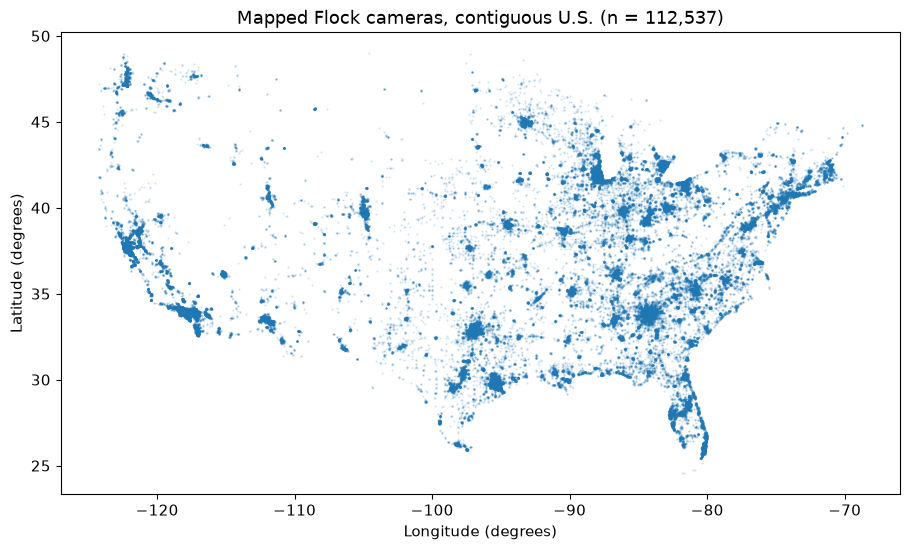

Cameras outside the contiguous U.S. box (Alaska, Hawaii, territories): 293


In [24]:
# Map of every camera in the contiguous U.S. With over 100,000 points, small
# transparent dots keep dense areas from turning into one solid blob.
contiguous = cameras.filter(pl.col("lon").is_between(-125, -66) & pl.col("lat").is_between(24, 50))
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(contiguous["lon"], contiguous["lat"], s=0.4, alpha=0.15, color="tab:blue")
ax.set_title(f"Mapped Flock cameras, contiguous U.S. (n = {contiguous.height:,})")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_aspect(1.25)  # roughly corrects east-west stretching at U.S. latitudes
plt.show()
print(f"Cameras outside the contiguous U.S. box (Alaska, Hawaii, territories): {cameras.height - contiguous.height:,}")

**Observation:** Of 112,830 cameras, 112,537 are in the contiguous U.S. They cluster in metro areas (Atlanta, Texas cities, California coast, Detroit, Florida) and are sparse in the Mountain West and Plains. 293 are in Alaska, Hawaii or the territories.

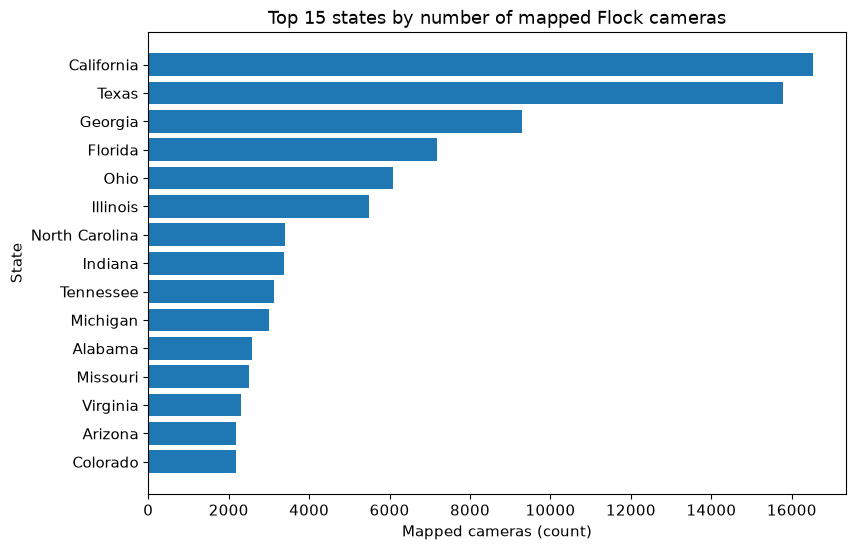

States with a camera: 51   top 5 share of cameras: 48.7%


state,cameras
str,u32
"""California""",16515
"""Texas""",15781
"""Georgia""",9297
"""Florida""",7176
"""Ohio""",6097


In [25]:
# Cameras per state, from the tract join (state = tract's state).
state_lookup = tracts.select(pl.col("GEOID").str.slice(0, 2).alias("state_fips"), "state").unique()
cameras_by_state = (
    camera_tracts.filter(pl.col("GEOID").is_not_null())
    .with_columns(pl.col("GEOID").str.slice(0, 2).alias("state_fips"))
    .join(state_lookup, on="state_fips", how="left")
    .group_by("state").len("cameras")
    .sort("cameras", descending=True)
)
top_states = cameras_by_state.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_states["state"].reverse(), top_states["cameras"].reverse(), color="tab:blue")
ax.set_title("Top 15 states by number of mapped Flock cameras")
ax.set_xlabel("Mapped cameras (count)")
ax.set_ylabel("State")
plt.show()
top_five_share = top_states.head(5)["cameras"].sum() / cameras_by_state["cameras"].sum() * 100
print(f"States with a camera: {cameras_by_state.height}   top 5 share of cameras: {top_five_share:.1f}%")
top_states.head(5)

**Observation:** Every state and DC has at least one mapped camera, and five states (California 16,515, Texas 15,781, Georgia 9,297, Florida, Ohio) hold 48.7% of them. These are raw counts, which partly track population; Step 4 compares states per resident.

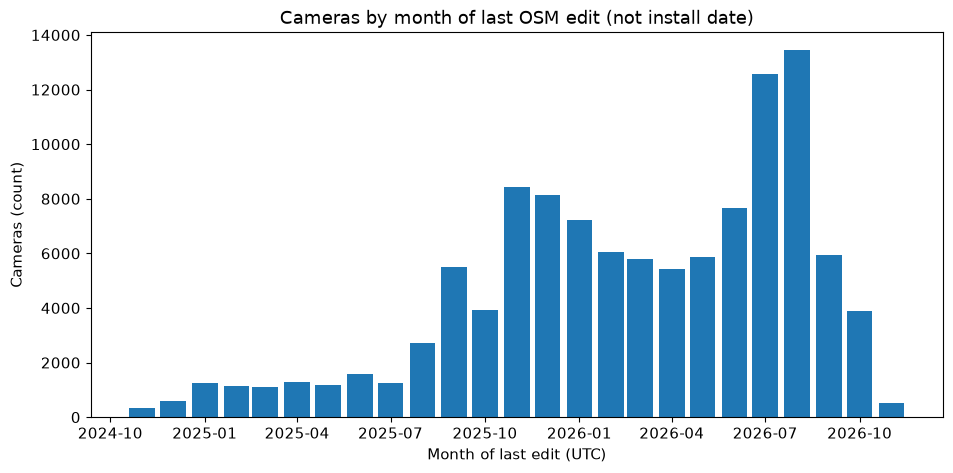

In [26]:
# Last-edit month. This is when each camera's OSM record was last changed.
edits_by_month = (
    cameras.group_by(pl.col("last_edit").dt.truncate("1mo").alias("month"))
    .len("cameras").sort("month")
)
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(edits_by_month["month"].to_list(), edits_by_month["cameras"].to_list(), width=25, color="tab:blue")
ax.set_title("Cameras by month of last OSM edit (not install date)")
ax.set_xlabel("Month of last edit (UTC)")
ax.set_ylabel("Cameras (count)")
plt.show()

In [27]:
last_edit_days = cameras.select(pl.col("last_edit").dt.date().alias("day"))["day"]
print(f"Median last edit: {last_edit_days.median()}")
print(f"Middle 50% of last edits: {last_edit_days.quantile(0.25)} to {last_edit_days.quantile(0.75)}")
busiest = edits_by_month.sort("cameras", descending=True).head(3)
busiest

Median last edit: 2026-03-26 00:00:00
Middle 50% of last edits: 2025-11-24 00:00:00 to 2026-07-21 00:00:00


month,cameras
"datetime[μs, UTC]",u32
2026-08-01 00:00:00 UTC,13432
2026-07-01 00:00:00 UTC,12557
2025-11-01 00:00:00 UTC,8426


**Observation (center and spread):** The median last edit is 2026-03-26, and the middle half of cameras were last edited between 2025-11-24 and 2026-07-21.

**Observation (skew and outliers):** Last edits pile up near the download date, peaking in August 2026 (13,432) and July 2026 (12,557). That shape is built in: any re-edit moves a camera to a recent month. November 2026 is a partial month (data ends 2026-11-05).

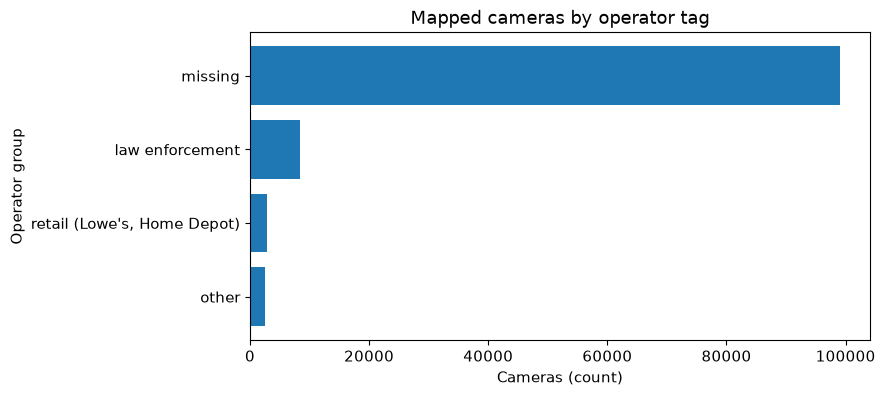

operator_group,count,pct
str,u32,f64
"""missing""",99134,87.9
"""law enforcement""",8322,7.4
"""retail (Lowe's, Home Depot)""",2833,2.5
"""other""",2541,2.3


In [28]:
# Who the operator tag names: police/sheriff, two retail chains, other, or missing.
LAW_ENFORCEMENT_PATTERN = r"(?i)police|sheriff|patrol|marshal|public safety|law enforcement|constable"
RETAIL_PATTERN = r"(?i)lowe'?s|home depot"
cameras = cameras.with_columns(
    pl.when(pl.col("operator").is_null()).then(pl.lit("missing"))
    .when(pl.col("operator").str.contains(LAW_ENFORCEMENT_PATTERN)).then(pl.lit("law enforcement"))
    .when(pl.col("operator").str.contains(RETAIL_PATTERN)).then(pl.lit("retail (Lowe's, Home Depot)"))
    .otherwise(pl.lit("other"))
    .alias("operator_group")
)
operator_groups = cameras["operator_group"].value_counts(sort=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(operator_groups["operator_group"].reverse(), operator_groups["count"].reverse(), color="tab:blue")
ax.set_title("Mapped cameras by operator tag")
ax.set_xlabel("Cameras (count)")
ax.set_ylabel("Operator group")
plt.show()
operator_groups.with_columns((pl.col("count") / cameras.height * 100).round(1).alias("pct"))

**Observation:** Among cameras with an operator tag, law enforcement is the largest group (8,322, 7.4% of all cameras), then the two retail chains (2,833, 2.5%) and other operators (2,541, 2.3%). "Other" includes `Flock Safety` itself and property companies.

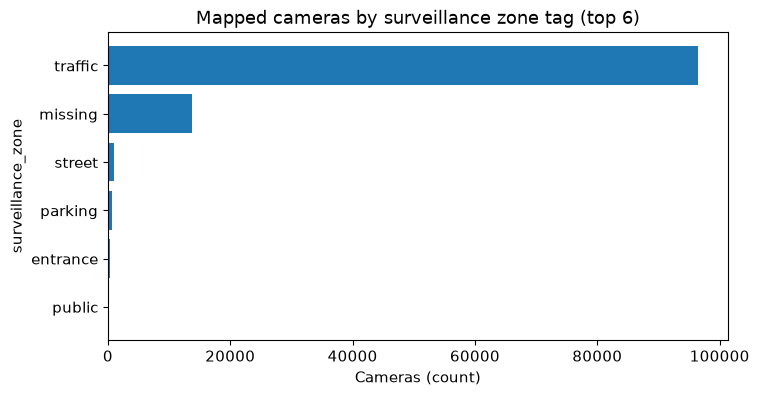

traffic share: 85.5%


In [29]:
zone_counts = cameras["surveillance_zone"].fill_null("missing").value_counts(sort=True).head(6)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(zone_counts["surveillance_zone"].reverse(), zone_counts["count"].reverse(), color="tab:blue")
ax.set_title("Mapped cameras by surveillance zone tag (top 6)")
ax.set_xlabel("Cameras (count)")
ax.set_ylabel("surveillance_zone")
plt.show()
print(f"traffic share: {(cameras['surveillance_zone'] == 'traffic').sum() / cameras.height * 100:.1f}%")

**Observation:** 85.5% of cameras are tagged `surveillance_zone=traffic`, so mapped cameras are mostly road-facing, not inside parking lots or buildings.

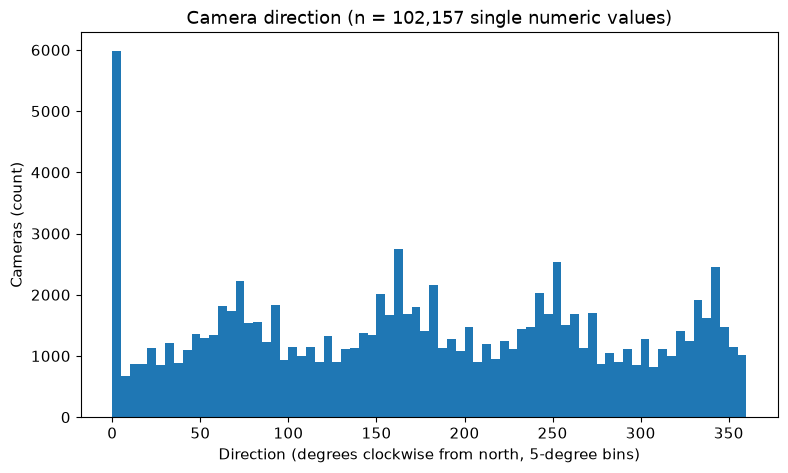

Exactly 0: 5,760   next most common 5-degree bin count: 2,742


In [30]:
# Camera heading in degrees (0 = north, 90 = east). Only single numbers in 0-360.
valid_direction = direction_numbers.filter(direction_numbers.is_between(0, 360))
fig, ax = plt.subplots()
ax.hist(valid_direction.to_numpy(), bins=np.arange(0, 365, 5), color="tab:blue")
ax.set_title(f"Camera direction (n = {valid_direction.len():,} single numeric values)")
ax.set_xlabel("Direction (degrees clockwise from north, 5-degree bins)")
ax.set_ylabel("Cameras (count)")
plt.show()
print(f"Exactly 0: {(valid_direction == 0).sum():,}   next most common 5-degree bin count: "
      f"{np.sort(np.histogram(valid_direction.to_numpy(), bins=np.arange(0, 365, 5))[0])[-2]:,}")

**Observation (center and spread):** Directions are spread over the whole circle; no compass direction is strongly preferred apart from 0.

**Observation (skew and outliers):** 0 is an outlier. 5,760 cameras face exactly 0 degrees, more than twice the next busiest 5-degree bin (2,742). Many of these zeros are probably defaults, not real northward cameras.

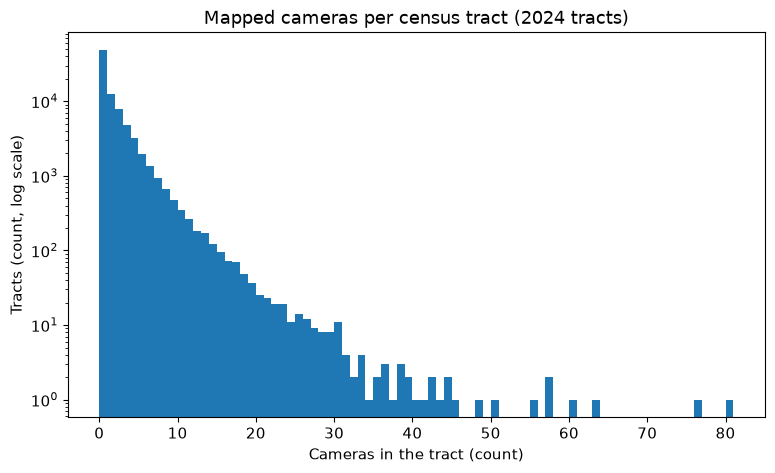

In [31]:
# Cameras per tract, zero-camera tracts included. Log y-axis because most
# tracts have 0 and a few have many.
fig, ax = plt.subplots()
ax.hist(tract_cameras["cameras"].to_numpy(), bins=np.arange(0, tract_cameras["cameras"].max() + 2), color="tab:blue")
ax.set_yscale("log")
ax.set_title("Mapped cameras per census tract (2024 tracts)")
ax.set_xlabel("Cameras in the tract (count)")
ax.set_ylabel("Tracts (count, log scale)")
plt.show()

In [32]:
per_tract = tract_cameras["cameras"]
print(f"Tracts: {per_tract.len():,}   with 0 cameras: {(per_tract == 0).sum():,} ({(per_tract == 0).mean() * 100:.1f}%)")
print(f"Mean: {per_tract.mean():.2f}   median: {per_tract.median():.0f}   75th percentile: {per_tract.quantile(0.75):.0f}")
print(f"Max: {per_tract.max()}   tracts with 20+ cameras: {(per_tract >= 20).sum():,}")
top_one_pct = per_tract.sort(descending=True).head(per_tract.len() // 100).sum()
print(f"Share of cameras in the top 1% of tracts: {top_one_pct / per_tract.sum() * 100:.1f}%")

Tracts: 84,401   with 0 cameras: 49,076 (58.1%)
Mean: 1.33   median: 0   75th percentile: 2
Max: 80   tracts with 20+ cameras: 198
Share of cameras in the top 1% of tracts: 13.4%


**Observation (center and spread):** Of 84,401 tracts, 49,076 (58.1%) have no mapped camera. The median is 0, the mean is 1.33, and the 75th percentile is 2.

**Observation (skew and outliers):** The distribution is strongly right-skewed: the maximum is 80 cameras in one tract, 198 tracts have 20 or more, and the top 1% of tracts hold 13.4% of all cameras.

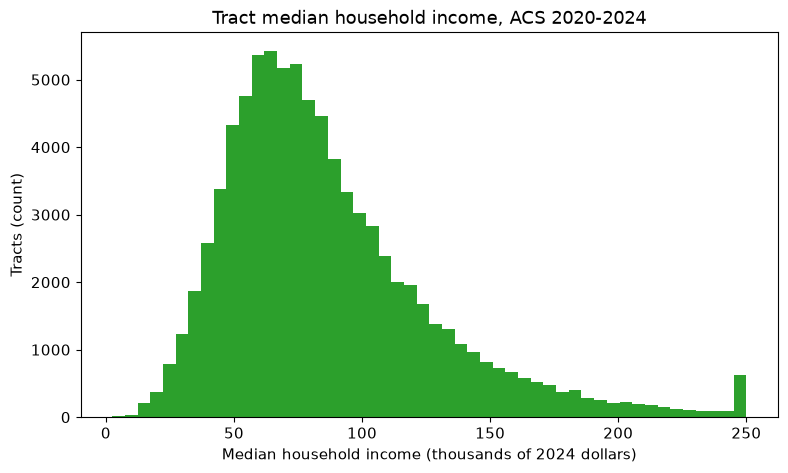

Median: $77,449   middle 50%: $58,108 to $105,000
Tracts at the 250,000 cap: 555


In [33]:
income_values = tract_cameras["median_income"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(income_values.to_numpy() / 1000, bins=50, color="tab:green")
ax.set_title("Tract median household income, ACS 2020-2024")
ax.set_xlabel("Median household income (thousands of 2024 dollars)")
ax.set_ylabel("Tracts (count)")
plt.show()
print(f"Median: ${income_values.median():,.0f}   middle 50%: ${income_values.quantile(0.25):,.0f} to ${income_values.quantile(0.75):,.0f}")
print(f"Tracts at the 250,000 cap: {(income_values == 250000).sum():,}")

**Observation (center and spread):** The median tract income is $77,449, and the middle half of tracts fall between $58,108 and $105,000.

**Observation (skew and outliers):** Income is right-skewed with a ceiling: 555 tracts sit at the $250,000 cap, so the true top values are unknown.

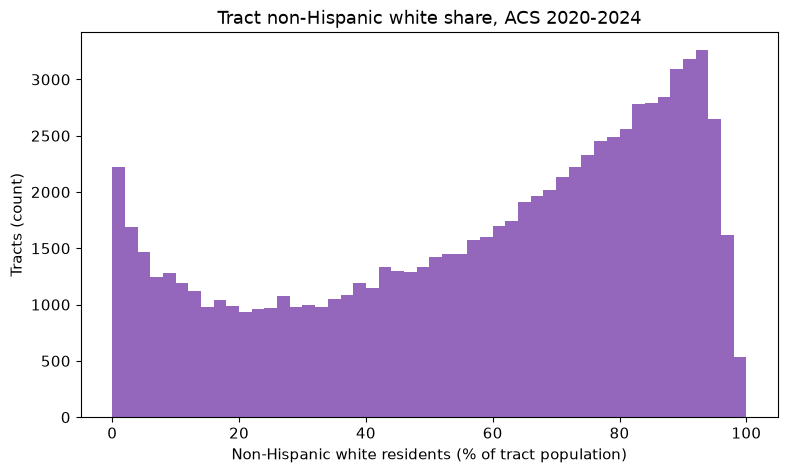

Median: 65.1%   middle 50%: 35.5% to 83.3%


In [34]:
white_values = tract_cameras["white_share_pct"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(white_values.to_numpy(), bins=50, color="tab:purple")
ax.set_title("Tract non-Hispanic white share, ACS 2020-2024")
ax.set_xlabel("Non-Hispanic white residents (% of tract population)")
ax.set_ylabel("Tracts (count)")
plt.show()
print(f"Median: {white_values.median():.1f}%   middle 50%: {white_values.quantile(0.25):.1f}% to {white_values.quantile(0.75):.1f}%")

**Observation (center and spread):** The median tract is 65.1% non-Hispanic white, and the middle half range from 35.5% to 83.3%, a very wide spread.

**Observation (skew and outliers):** The shape is left-skewed: many tracts are 80-100% white, with a long tail down to 0%.

## Step 4: Relationships

Groups are compared per 10,000 residents, not by raw counts, so large groups do
not look worse just for being large. Rates are total cameras divided by total
population in each group. Tracts with population 0 or no income estimate are left out.

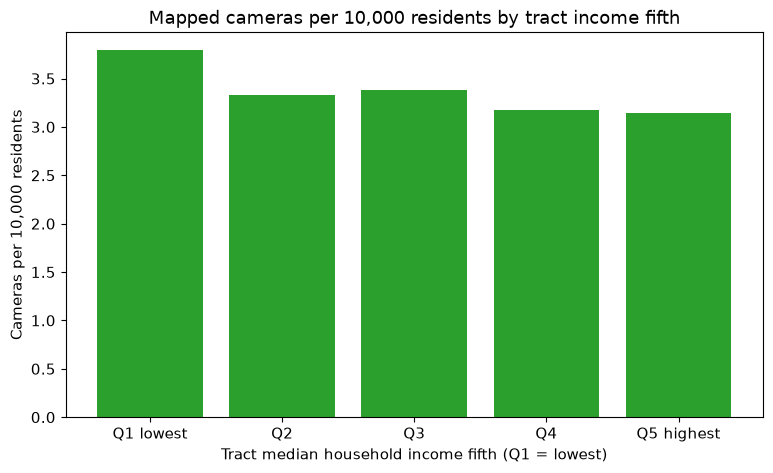

quintile,tracts,min,max,cameras,population,per_10k
cat,u32,f64,f64,u32,i64,f64
"""Q1 lowest""",16583,2500.0,53804.0,20756,54694717,3.79
"""Q2""",16582,53806.0,69588.0,20767,62433351,3.33
"""Q3""",16585,69591.0,86406.0,22782,67305578,3.38
"""Q4""",16580,86408.0,113778.0,23063,72528867,3.18
"""Q5 highest""",16583,113786.0,250000.0,24015,76499290,3.14


In [35]:
# Fifths (quintiles) of tracts: each holds about the same number of tracts.
rate_tracts = tract_cameras.filter(pl.col("population") > 0)
QUINTILE_LABELS = ["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]


def rate_by_quintile(table: pl.DataFrame, column_name: str) -> pl.DataFrame:
    """Cameras per 10,000 residents in each fifth of tracts ranked by column_name."""
    return (
        table.filter(pl.col(column_name).is_not_null())
        .with_columns(pl.col(column_name).qcut(5, labels=QUINTILE_LABELS).alias("quintile"))
        .group_by("quintile")
        .agg(
            pl.len().alias("tracts"),
            pl.col(column_name).min().round(1).alias("min"),
            pl.col(column_name).max().round(1).alias("max"),
            pl.col("cameras").sum(),
            pl.col("population").sum(),
        )
        .with_columns((pl.col("cameras") / pl.col("population") * 10_000).round(2).alias("per_10k"))
        .sort("quintile")
    )


income_quintiles = rate_by_quintile(rate_tracts, "median_income")
fig, ax = plt.subplots()
ax.bar(income_quintiles["quintile"].cast(pl.String), income_quintiles["per_10k"], color="tab:green")
ax.set_title("Mapped cameras per 10,000 residents by tract income fifth")
ax.set_xlabel("Tract median household income fifth (Q1 = lowest)")
ax.set_ylabel("Cameras per 10,000 residents")
plt.show()
income_quintiles

**Observation:** The lowest-income fifth of tracts has the most mapped cameras per resident (3.79 per 10,000) and the highest-income fifth the fewest (3.14). The middle fifths sit between 3.18 and 3.38, so the gap is small.

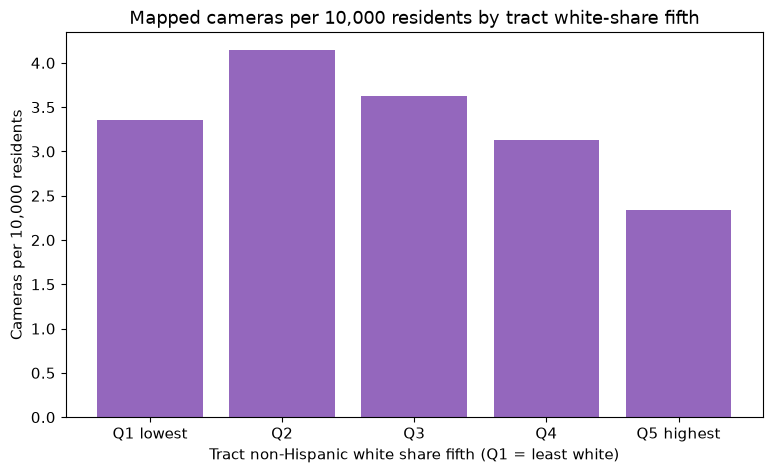

quintile,tracts,min,max,cameras,population,per_10k
cat,u32,f64,f64,u32,i64,f64
"""Q1 lowest""",16722,0.0,27.2,22544,67175453,3.36
"""Q2""",16721,27.2,55.0,29176,70490590,4.14
"""Q3""",16722,55.0,73.2,25056,69055577,3.63
"""Q4""",16721,73.2,86.3,21165,67600655,3.13
"""Q5 highest""",16722,86.3,100.0,14172,60522645,2.34


In [36]:
white_quintiles = rate_by_quintile(rate_tracts, "white_share_pct")
fig, ax = plt.subplots()
ax.bar(white_quintiles["quintile"].cast(pl.String), white_quintiles["per_10k"], color="tab:purple")
ax.set_title("Mapped cameras per 10,000 residents by tract white-share fifth")
ax.set_xlabel("Tract non-Hispanic white share fifth (Q1 = least white)")
ax.set_ylabel("Cameras per 10,000 residents")
plt.show()
white_quintiles

**Observation:** The whitest fifth of tracts (86.3-100% white) has the fewest mapped cameras per resident (2.34 per 10,000). The peak is the second fifth (27.2-55.0% white) at 4.14, and the least-white fifth is 3.36, so the pattern rises and then falls.

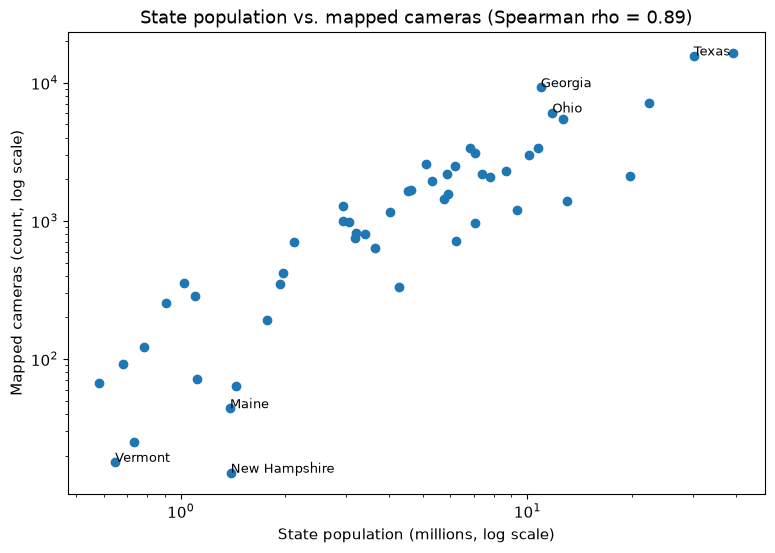

States + DC: 51   states with 0 cameras: 0   Spearman rho: 0.895


state,cameras,population,per_10k
str,u32,i64,f64
"""Georgia""",9297,10940407,8.5
"""Texas""",15781,30188424,5.23
"""Ohio""",6097,11810293,5.16
"""Alabama""",2579,5086768,5.07
"""Indiana""",3385,6851073,4.94


In [37]:
# State level: do states with more people have more mapped cameras?
# Log scales, because state populations range from about 0.6 to 39 million.
state_population = tracts.join(shape_geoids, on="GEOID", how="semi").group_by("state").agg(pl.col("population").sum())
state_table = (
    state_population.join(cameras_by_state, on="state", how="left")
    .with_columns(pl.col("cameras").fill_null(0))
    .with_columns((pl.col("cameras") / pl.col("population") * 10_000).round(2).alias("per_10k"))
)
spearman = state_table.select(pl.corr("population", "cameras", method="spearman")).item()

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(state_table["population"] / 1e6, state_table["cameras"], color="tab:blue")
# Label the three highest and three lowest states by cameras per resident.
labelled = pl.concat([state_table.sort("per_10k").head(3), state_table.sort("per_10k").tail(3)])
for row in labelled.iter_rows(named=True):
    ax.annotate(row["state"], (row["population"] / 1e6, row["cameras"]), fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title(f"State population vs. mapped cameras (Spearman rho = {spearman:.2f})")
ax.set_xlabel("State population (millions, log scale)")
ax.set_ylabel("Mapped cameras (count, log scale)")
plt.show()
print(f"States + DC: {state_table.height}   states with 0 cameras: {(state_table['cameras'] == 0).sum()}   Spearman rho: {spearman:.3f}")
state_table.sort("per_10k", descending=True).select("state", "cameras", "population", "per_10k").head(5)

**Observation:** States with more people have more mapped cameras (Spearman rho = 0.895). Per resident, Georgia leads with 8.5 cameras per 10,000, ahead of Texas (5.23) and Ohio (5.16).

In [38]:
state_table.sort("per_10k").select("state", "cameras", "population", "per_10k").head(5)

state,cameras,population,per_10k
str,u32,i64,f64
"""New Hampshire""",15,1394868,0.11
"""Vermont""",18,647106,0.28
"""Maine""",44,1387817,0.32
"""Alaska""",25,735706,0.34
"""Hawaii""",64,1445235,0.44


**Observation:** The lowest rates are in small northern states: New Hampshire 0.11, Vermont 0.28 and Maine 0.32 cameras per 10,000 residents.

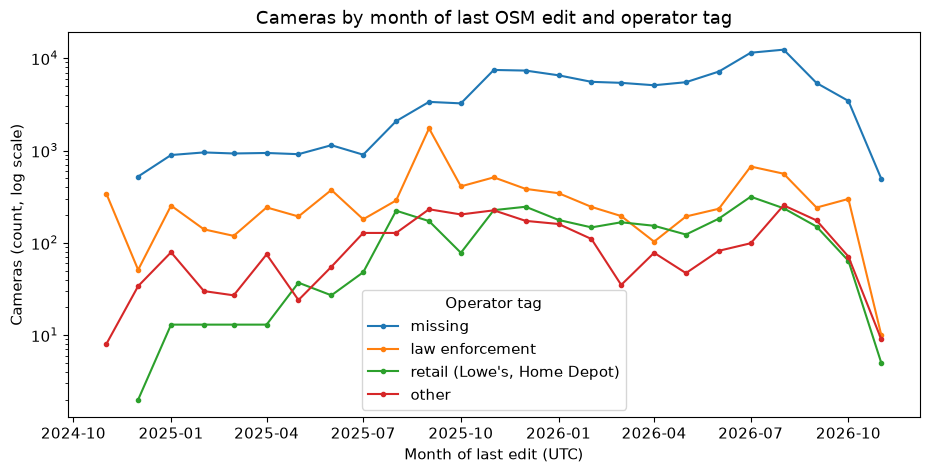

last_edit_year,cameras,operator_tagged_pct
i32,u32,f64
2024,960,45.5
2025,37493,19.5
2026,74377,8.0


In [39]:
# Time series: last-edit month for each operator group.
edits_by_group = (
    cameras.group_by(pl.col("last_edit").dt.truncate("1mo").alias("month"), "operator_group")
    .len("cameras").sort("month")
)
fig, ax = plt.subplots(figsize=(11, 5))
for group_name in ["missing", "law enforcement", "retail (Lowe's, Home Depot)", "other"]:
    group_rows = edits_by_group.filter(pl.col("operator_group") == group_name)
    ax.plot(group_rows["month"].to_list(), group_rows["cameras"].to_list(), marker="o", markersize=3, label=group_name)
ax.set_yscale("log")
ax.set_title("Cameras by month of last OSM edit and operator tag")
ax.set_xlabel("Month of last edit (UTC)")
ax.set_ylabel("Cameras (count, log scale)")
ax.legend(title="Operator tag")
plt.show()

# Share of each last-edit year whose operator is tagged.
cameras.group_by(pl.col("last_edit").dt.year().alias("last_edit_year")).agg(
    pl.len().alias("cameras"),
    (pl.col("operator_group") != "missing").mean().mul(100).round(1).alias("operator_tagged_pct"),
).sort("last_edit_year")

**Observation:** Operator tags are rarer on recently edited records: 45.5% of cameras last edited in 2024 name an operator, 19.5% in 2025, and 8.0% in 2026. The "missing" line is the largest group in every month from December 2024 on.

## Step 5: So what?

**So what? (income fifths plot)**

- **Observation:** Mapped cameras per resident fall slightly as tract income rises (3.79 to 3.14 per 10,000).
- **Why it matters:** For research question 2, income alone shows at most a weak link to mapped camera density.
- **Tag: In between.** Some link was expected, but the gap is small, and these are group averages that say nothing about individual households.

**So what? (white-share fifths plot)**

- **Observation:** The whitest fifth of tracts has the lowest rate (2.34 per 10,000), and mixed tracts the highest (4.14).
- **Why it matters:** Racial composition goes with mapped density more strongly than income does, which makes it the stronger lead for research question 2.
- **Tag: Unexpected.** The pattern is not a straight line, and it could reflect where these tracts are (cities, regions) rather than composition itself.

**So what? (state scatter)**

- **Observation:** Population predicts state camera counts well (rho = 0.895), yet per-resident rates range from 0.11 (New Hampshire) to 8.5 (Georgia).
- **Why it matters:** State differences are large, so national tract comparisons partly compare states. Research questions 1 and 2 need state-aware comparisons.
- **Tag: In between.** More cameras in bigger states is expected; the size of the per-resident gap is not.

**So what? (operator tag time series)**

- **Observation:** The share of cameras with an operator tag drops from 45.5% (last edited 2024) to 8.0% (2026).
- **Why it matters:** Any analysis of who operates cameras would lean on the older-edited records, and the recent wave of mapping adds cameras with less detail. That affects how research question 1 describes the growth of the map.
- **Tag: Unexpected.** More recent edits were expected to add detail, not less.

## Step 6: What next? and revised research questions

**What next? (income fifths plot):** Rank tracts by income *within their own state* and recompute the rates, to see whether the small gap survives once state differences are removed.

**What next? (white-share fifths plot):** Split the fifths by population density (people per square kilometre, using tract area in a projected coordinate system) to see whether the peak in mixed tracts is a city effect.

**What next? (state scatter):** Join the Finding Flock state counts to check whether low states such as New Hampshire have fewer cameras or just less mapping, and ask an OSM mapping community about regional mapping campaigns.

**What next? (operator tag time series):** Join the OSM history file and use `first_tagged_date` (first mapped) instead of `timestamp`, to see whether newly mapped cameras arrive without an operator tag.

### Revised research questions

1. **(revised)** Where are mapped Flock cameras, and how has the mapping grown over time, measured with first-mapped dates from the history file? *Changed because* `timestamp` here is the last edit, so this file cannot measure growth.
2. **(revised)** Is mapped camera density *per resident* associated with tract income and racial composition *within states*? *Changed because* state rates differ from 0.11 to 8.5 per 10,000, and the income and race patterns need a fair, state-aware comparison.
3. **(unchanged)** Is mapped camera density associated with political voting patterns? Not tested here; it needs the county election join.
4. **(new)** How complete is the mapping itself, and does tag detail (such as `operator`) differ by place and time? *Added because* `operator` is missing for 87.9% of cameras and its share falls among recently edited records.